<a href="https://colab.research.google.com/github/SamuelBG-SVG/Proyecto---Grietas/blob/main/06_Transfer_Learning(completo).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os


base_dir = '/content/drive/MyDrive/Proyecto_Grietas/data'


train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='training',
    seed=42
)

val_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='validation',
    seed=42
)

print(f"• Clases detectadas: {train_generator.class_indices}")

Found 36127 images belonging to 2 classes.
Found 9031 images belonging to 2 classes.
• Clases detectadas: {'Negative': 0, 'Positive': 1}


In [3]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam


base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')


base_model.trainable = False


x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)  # Dropout para evitar sobreajuste
predictions = Dense(1, activation='sigmoid')(x) # Salida binaria

model = Model(inputs=base_model.input, outputs=predictions)


model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
import os
import zipfile

ruta_zip = '/content/drive/MyDrive/Proyecto_Grietas/dataset.zip'
carpeta_destino = '/content/dataset_local'

print("📦 Descomprimiendo dataset y sobrescribiendo automáticamente...")
!unzip -o -q {ruta_zip} -d {carpeta_destino}


📦 Descomprimiendo dataset y sobrescribiendo automáticamente...


In [11]:
import os

ruta_base = '/content/dataset_local'
print("Contenido directo en dataset_local:", os.listdir(ruta_base))

Contenido directo en dataset_local: ['data']


In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import tensorflow as tf


base_dir = '/content/dataset_local/data'

print("🔄 Configurando generadores de datos desde el disco local...")
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='training',
    seed=42
)

val_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='validation',
    seed=42
)

print(f"✅ Clases detectadas con éxito: {train_generator.class_indices}")


print("🏗️ Construyendo el modelo MobileNetV2...")
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

for layer in base_model.layers:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
predictions = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=['accuracy'])


print("🚀 Iniciando entrenamiento local de 10 épocas...")
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
]

history = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator,
    callbacks=callbacks
)

🔄 Configurando generadores de datos desde el disco local...
Found 36127 images belonging to 2 classes.
Found 9031 images belonging to 2 classes.
✅ Clases detectadas con éxito: {'Negative': 0, 'Positive': 1}
🏗️ Construyendo el modelo MobileNetV2...
🚀 Iniciando entrenamiento local de 10 épocas...
Epoch 1/10
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 2993s 3s/step - accuracy: 0.9594 - loss: 0.1089 - val_accuracy: 0.9916 - val_loss: 0.0308
Epoch 2/10
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 2898s 3s/step - accuracy: 0.9827 - loss: 0.0529 - val_accuracy: 0.9880 - val_loss: 0.0370
Epoch 3/10
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 2905s 3s/step - accuracy: 0.9859 - loss: 0.0425 - val_accuracy: 0.9919 - val_loss: 0.0253
Epoch 4/10
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 2915s 3s/step - accuracy: 0.9872 - loss: 0.0381 - val_accuracy: 0.9935 - val_loss: 0.0213
Epoch 5/10
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 2918s 3s/step - accuracy: 0.9889 - loss: 0.0336 - val_accuracy: 0.9896 - val_loss: 0.0337
Epoch 6/10
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 29

In [14]:
import os

drive_dir = '/content/drive/MyDrive/Proyecto_Grietas'
os.makedirs(drive_dir, exist_ok=True)
ruta_modelo_final = os.path.join(drive_dir, 'modelo_grietas_final.keras')

model.save(ruta_modelo_final)
print(f"✅ ¡Modelo final guardado con éxito en: {ruta_modelo_final}")

✅ ¡Modelo final guardado con éxito en: /content/drive/MyDrive/Proyecto_Grietas/modelo_grietas_final.keras


283/283 ━━━━━━━━━━━━━━━━━━━━ 633s 2s/step
📊 Reporte de Clasificación:

              precision    recall  f1-score   support

    Negative       0.35      0.35      0.35      3335
    Positive       0.62      0.62      0.62      5696

    accuracy                           0.52      9031
   macro avg       0.49      0.49      0.49      9031
weighted avg       0.52      0.52      0.52      9031



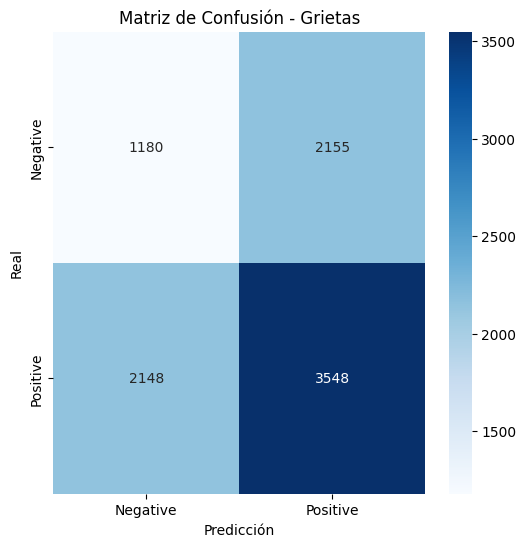

In [15]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Reiniciar el generador de validación para asegurar orden
val_generator.reset()

# Obtener predicciones (probabilidades)
Y_pred = model.predict(val_generator)
y_pred_classes = (Y_pred > 0.5).astype("int32").ravel()

# Obtener las etiquetas reales
y_true = val_generator.classes

# 1. Reporte de Clasificación
print("📊 Reporte de Clasificación:\n")
print(classification_report(y_true, y_pred_classes, target_names=list(val_generator.class_indices.keys())))

# 2. Matriz de Confusión
conf_matrix = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=val_generator.class_indices.keys(),
            yticklabels=val_generator.class_indices.keys())
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión - Grietas')
plt.show()

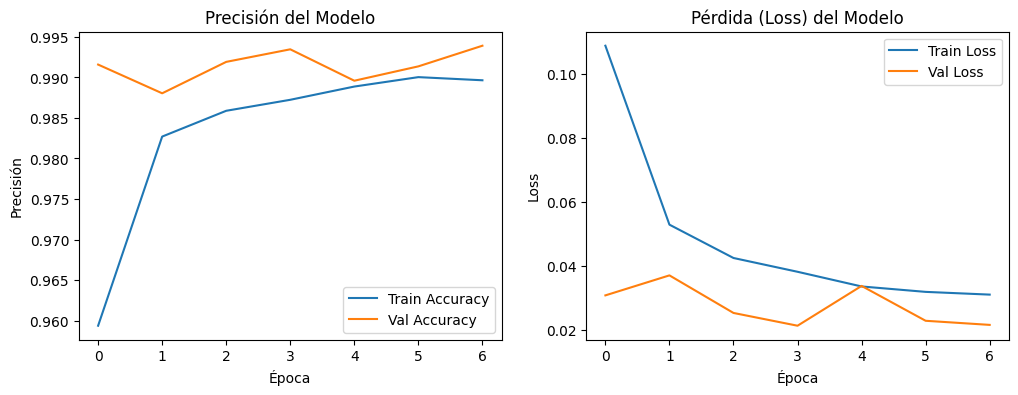

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Gráfica de Precisión
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Precisión del Modelo')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()

# Gráfica de Pérdida
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Pérdida (Loss) del Modelo')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

plt.show()